# Metric re-check: which metric does Kaggle really use?

หน้า Overview บอกว่างาน 1 ใช้ "F2 (Macro)" แต่ Kaggle ให้คะแนนด้วย F2 ของคลาสคนโกงอย่างเดียว ที่ไม่มีใครเห็นเพราะทีมเทียบแค่**ส่วนต่าง**ของคะแนน (CV +0.0032 กับ Kaggle +0.0029) ซึ่ง metric ผิดก็ยังให้ส่วนต่างใกล้กันได้ ส่วน**ระดับ**คะแนนไม่ตรง (CV macro 0.78 กับ Kaggle ประมาณ 0.76)

notebook นี้เช็คงาน 2 ถึง 5 แบบเดียวกัน: เอา OOF ของโมเดลปัจจุบันมาคิดคะแนนด้วยทุกนิยามที่เป็นไปได้ แล้วเทียบ**ระดับ**กับคะแนนบน Kaggle ของงานนั้น นิยามที่ห่างจาก Kaggle ไม่เกิน 0.005 ถือว่า "consistent" ถ้าระดับบอกไม่ได้ ใช้ส่วนต่างจากการสลับคอลัมน์เดียวที่รู้แน่ว่าเปลี่ยนแค่งานนั้นเป็นหลักฐานรอง

วิเคราะห์อย่างเดียว ไม่แก้ `pis/`, `run.py` หรือ `Task*/train.py` และไม่ submit

## Imports

In [1]:
import os, sys
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score, fbeta_score

pd.set_option('display.width', 200)  # keep wide tables on one line instead of "..."

## Setup

In [2]:
# Find the repo root (the folder with `run.py`), move there and add it to `sys.path`, so paths like `outputs/...` and `import pis` work wherever the kernel started.
ROOT = Path.cwd().resolve()
while not (ROOT / 'run.py').exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError('run.py not found; open this notebook inside the repo')
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from pis.common import DEFAULT_DATA   # ../cpe342-kaggle-main, needs ROOT on sys.path
from pis.tabular import _score        # Task 3 score used by the pipeline: 1 / (1 + sum|y - p| / sum y)

BLUE, RED, ORANGE, INK, GRID = '#2a78d6', '#e34948', '#eb6834', '#52514e', '#e5e4df'
TOL = 0.005  # "consistent" = within 0.005 of the Kaggle level


def tidy(ax, grid='x'):
    ax.grid(axis=grid, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)


def level_table(levels, kaggle, test=True):
    # levels: {definition: OOF level}. Adds the distance from the Kaggle level and the verdict.
    t = pd.Series(levels, name='OOF level').to_frame()
    t['Kaggle'] = kaggle
    t['distance'] = t['OOF level'] - kaggle
    t['consistent'] = np.where(t['distance'].abs() <= TOL, 'yes', '') if test else 'not tested'
    return t


def plot_levels(table, kaggle, title, label='Kaggle level'):
    t = table.iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(t) + 1.2))
    ok = t['consistent'] == 'yes'
    ax.scatter(t['OOF level'], t.index, s=60, color=[BLUE if o else '#a9c8ee' for o in ok], zorder=3)
    ax.axvspan(kaggle - TOL, kaggle + TOL, color=ORANGE, alpha=0.15, lw=0)
    ax.axvline(kaggle, color=ORANGE, linewidth=1.5)
    ax.text(kaggle, len(t) - 0.4, f' {label} {kaggle:.3f}', color=INK, fontsize=9, va='bottom')
    for name, v in t['OOF level'].items():
        ax.text(v, name, f'  {v:.4f}', va='center', fontsize=8, color=INK)
    ax.set_ylim(-0.6, len(t) + 0.2)
    ax.set_xlabel('OOF level under each definition (band = Kaggle ± 0.005)')
    ax.set_title(title, loc='left')
    ax.tick_params(axis='y', length=0, labelsize=9)
    tidy(ax)
    plt.tight_layout()
    plt.show()


print(f"repo root: {ROOT}")

repo root: C:\Users\acer\Desktop\cpe342\project\player-intelligence-system-cpe342


## Kaggle levels used here

ระดับของแต่ละงานบน Kaggle มาจากการสลับคอลัมน์เดียว (ไฟล์ฐาน 0.82343) ตามที่สรุปไว้ใน `docs/KAGGLE_FINDINGS_TH.md` บน branch `task3-staging` (ส่วน "คะแนนแต่ละงานบน Kaggle", 20 พ.ย.) และตัวเลขใน prompt ไม่มีที่ไหนใน repo หรือ description ของ PR ที่ให้ตัวเลขละเอียดกว่านี้ ส่วนต่างที่รู้แน่ว่าเปลี่ยนแค่งานเดียว (ใช้เป็นหลักฐานรอง):

- งาน 1: 0.82343 → 0.83699 เมื่อลด threshold จาก 0.386 เป็นประมาณ 0.18 (Task 1 notebook `Task1/eda/missing_eda.ipynb`)
- งาน 2: 0.72692 → 0.72792 เมื่อเปลี่ยน CatBoost เป็น NB × CatBoost (`Task2/README.md`)
- งาน 3: V9a refit บนฐาน 0.82343 ได้ 0.82369 (`docs/KAGGLE_FINDINGS_TH.md` บน `task3-staging`)
- งาน 5: 0.72635 → 0.80097 เมื่อเปลี่ยน IsolationForest เป็น EB v1 (commit d873cb8: "Tasks 1-4 unchanged from baseline")

ส่วนต่างของคะแนนรวม × 5 = ส่วนต่างของงานนั้น (คะแนนรวมเป็นค่าเฉลี่ย 5 งานน้ำหนักเท่ากัน ยืนยันแล้วจากการสลับทีละงาน)

In [3]:
KAGGLE = {'T2': 0.753, 'T3 (V8 refit)': 0.793, 'T4 (ens18)': 0.824, 'T5': 0.99}
SWAPS = pd.DataFrame([
    ('T1', 'threshold 0.386 -> ~0.18', 0.82343, 0.83699),
    ('T2', 'CatBoost -> NB x CatBoost', 0.72692, 0.72792),
    ('T3', 'V8 refit -> V9a refit', 0.82343, 0.82369),
    ('T5', 'IsolationForest 20% -> EB v1 (auto, 2,008 flags)', 0.72635, 0.80097),
], columns=['task', 'change', 'total before', 'total after']).set_index('task')
SWAPS['task delta (x5)'] = 5 * (SWAPS['total after'] - SWAPS['total before'])
SWAPS.style.format({'total before': '{:.5f}', 'total after': '{:.5f}', 'task delta (x5)': '{:+.4f}'}).set_caption('Single-task swaps on Kaggle')

,change,total before,total after,task delta (x5)
task,,,,
T1,threshold 0.386 -> ~0.18,0.82343,0.83699,+0.0678
T2,CatBoost -> NB x CatBoost,0.72692,0.72792,+0.0050
T3,V8 refit -> V9a refit,0.82343,0.82369,+0.0013
T5,"IsolationForest 20% -> EB v1 (auto, 2,008 flags)",0.72635,0.80097,+0.3731


## 1. Task 1 as the calibration case

งาน 1 รู้คำตอบแล้ว (Kaggle = F2 ของคลาสคนโกง) ใช้ทดสอบวิธีนี้ก่อน: OOF 3 fold ของโมเดลปัจจุบัน (`outputs/experiments/task1_oof.csv` จาก `Task1/eda/make_oof.py`, 12 threads) คิดคะแนนที่ threshold เดิม (0.380, เลือกตาม macro F2) และ threshold ใหม่ (0.1805, เลือกตาม F2 คนโกง) แล้วเทียบส่วนต่างกับ Kaggle (+0.0678)

In [4]:
t1 = pd.read_csv('outputs/experiments/task1_oof.csv')
y1, p1 = t1['target'].to_numpy().astype(int), t1['probability_1'].to_numpy()


def task1_defs(pred):
    return {'macro F2': fbeta_score(y1, pred, beta=2, average='macro'), 'F2 cheater (binary)': fbeta_score(y1, pred, beta=2),
            'F2 legit': fbeta_score(1 - y1, 1 - pred, beta=2), 'weighted F2': fbeta_score(y1, pred, beta=2, average='weighted'),
            'micro F2 (= accuracy)': accuracy_score(y1, pred)}


old, new = task1_defs((p1 >= 0.380).astype(int)), task1_defs((p1 >= 0.1805).astype(int))
t1_table = pd.DataFrame({'threshold 0.380': old, 'threshold 0.1805': new})
t1_table['OOF delta'] = t1_table['threshold 0.1805'] - t1_table['threshold 0.380']
t1_table['Kaggle delta'] = SWAPS.loc['T1', 'task delta (x5)']
t1_table['delta gap'] = t1_table['OOF delta'] - t1_table['Kaggle delta']
t1_table.style.format('{:+.4f}', subset=['OOF delta', 'Kaggle delta', 'delta gap']).format('{:.4f}', subset=['threshold 0.380', 'threshold 0.1805']) \
    .set_caption('Task 1: each definition at the old and new threshold (3-fold OOF)')

,threshold 0.380,threshold 0.1805,OOF delta,Kaggle delta,delta gap
macro F2,0.7806,0.7165,-0.0641,+0.0678,-0.1319
F2 cheater (binary),0.7633,0.8380,+0.0748,+0.0678,+0.0070
F2 legit,0.7979,0.5949,-0.2029,+0.0678,-0.2707
weighted F2,0.7858,0.6799,-0.1059,+0.0678,-0.1737
micro F2 (= accuracy),0.7853,0.6940,-0.0913,+0.0678,-0.1591


**NOTE:**


The method works on the known case. Only F2 of the cheater class moves the way Kaggle did (+0.0748 on OOF vs +0.0678 on Kaggle). Macro, weighted, micro and legit-class F2 all fall when the threshold drops, the opposite direction. The level fits too: at the old threshold, cheater F2 is 0.763 against the ~0.76 seen on Kaggle, while macro F2 is 0.781. So a definition has to match both the level and the direction of a known change.

## 2. Task 2 (Overview: F1 Macro)

OOF 3 fold ของโมเดลปัจจุบัน (NB 0.6 × CatBoost 0.4, `outputs/experiments/task2_oof.csv` จาก `Task2/eda/make_oof.py`, 12 threads) กฎตัดสิน = argmax ไม่มีน้ำหนักคลาส นิยาม: macro, weighted, micro (= accuracy) และ F1 ของแต่ละคลาส

หลักฐานรอง: ส่วนต่างตอนเปลี่ยนจาก CatBoost อย่างเดียว (`baseline/task2_oof.csv`) เป็น blend เทียบกับ Kaggle +0.0050

class shares in train: [0.39381731 0.25030769 0.20220192 0.15367308] | CatBoost-only baseline macro F1 0.7516


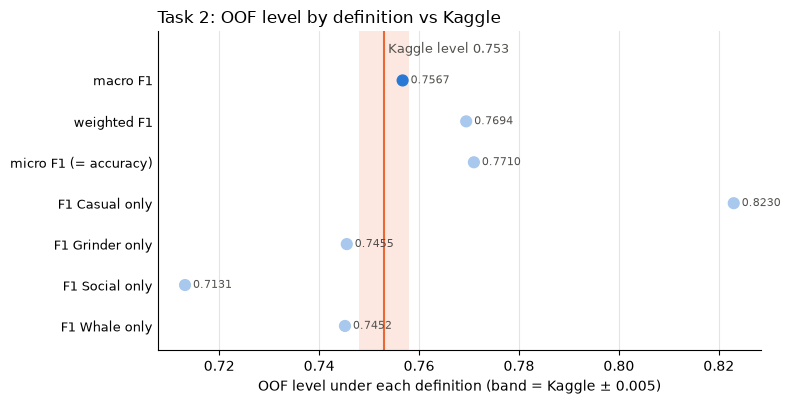

,OOF level,Kaggle,distance,consistent,OOF delta (CatBoost -> blend),Kaggle delta
macro F1,0.7567,0.753,+0.0037,yes,+0.0051,+0.0050
weighted F1,0.7694,0.753,+0.0164,,+0.0045,+0.0050
micro F1 (= accuracy),0.7710,0.753,+0.0180,,+0.0043,+0.0050
F1 Casual only,0.8230,0.753,+0.0700,,+0.0030,+0.0050
F1 Grinder only,0.7455,0.753,-0.0075,,+0.0035,+0.0050
F1 Social only,0.7131,0.753,-0.0399,,+0.0059,+0.0050
F1 Whale only,0.7452,0.753,-0.0078,,+0.0079,+0.0050


In [5]:
t2 = pd.read_csv('outputs/experiments/task2_oof.csv')
NAMES = ['Casual', 'Grinder', 'Social', 'Whale']
y2 = t2['target'].to_numpy().astype(int)
pred2 = t2[sorted(c for c in t2.columns if c.startswith('probability_'))].to_numpy().argmax(axis=1)
assert abs(f1_score(y2, pred2, average='macro') - 0.7567) < 5e-4, 'Task 2 OOF does not reproduce the README (0.7567)'


def task2_defs(y, pred):
    d = {'macro F1': f1_score(y, pred, average='macro'), 'weighted F1': f1_score(y, pred, average='weighted'),
         'micro F1 (= accuracy)': accuracy_score(y, pred)}
    d.update({f'F1 {n} only': v for n, v in zip(NAMES, f1_score(y, pred, average=None))})
    return d


t2_table = level_table(task2_defs(y2, pred2), KAGGLE['T2'])
base2 = pd.read_csv('baseline/task2_oof.csv')
assert (base2['player_id'].to_numpy() == t2['player_id'].to_numpy()).all()
base_pred = base2[sorted(c for c in base2.columns if c.startswith('probability_'))].to_numpy().argmax(axis=1) \
    if any(c.startswith('probability_') for c in base2.columns) else base2['prediction'].to_numpy().astype(int)
t2_table['OOF delta (CatBoost -> blend)'] = pd.Series(task2_defs(y2, pred2)) - pd.Series(task2_defs(y2, base_pred))
t2_table['Kaggle delta'] = SWAPS.loc['T2', 'task delta (x5)']
print(f"class shares in train: {np.bincount(y2) / len(y2)} | CatBoost-only baseline macro F1 {f1_score(y2, base_pred, average='macro'):.4f}")
plot_levels(t2_table, KAGGLE['T2'], 'Task 2: OOF level by definition vs Kaggle')
t2_table.style.format({'OOF level': '{:.4f}', 'Kaggle': '{:.3f}', 'distance': '{:+.4f}', 'OOF delta (CatBoost -> blend)': '{:+.4f}',
                       'Kaggle delta': '{:+.4f}'}).set_caption('Task 2: definitions, levels and the CatBoost -> blend delta')

**NOTE:**


**Macro F1 is the only consistent definition.** OOF 0.7567 is +0.0037 from Kaggle's 0.753; the 3-fold OOF runs a little high, as in Task 1 and Task 3. Weighted F1 (0.769) and micro F1 / accuracy (0.771) are 0.016 to 0.018 too high. The closest single classes, Grinder (−0.0075) and Whale (−0.0078), are outside the band.

The CatBoost → blend delta cannot separate them: macro +0.0051, weighted +0.0045, micro +0.0043 against Kaggle +0.0050. This is the trap from Task 1: deltas agree across definitions, only the level discriminates. A Task 1-style bug (sklearn's default `average='binary'`) cannot happen silently here either: on a 4-class target sklearn raises an error unless an average is given.

## 3. Task 3 (Overview: NMAE)

OOF ของ V8 (`outputs/experiments/task3_v8/task3_oof.csv`, ตัวที่อยู่ในไฟล์ฐาน 0.82343, Kaggle 0.793) และ V9a (`outputs/experiments/task3_v9a/task3_oof.csv`, ตัวสุดท้าย, Kaggle ประมาณ 0.793 + 0.0013) จาก `experiments/task3/model/` บน `task3-staging` (KFold 3, seed 342, honest early stopping) เช็คว่าได้ OOF ตรงกับ `champion.json` ก่อน

NMAE หลายแบบ: MAE หารด้วย mean(|y|), (max − min), std, IQR, median ของยอดที่ไม่เป็น 0 และ mean(|y − ŷ| / |y|) บนแถวที่ y > 0 (y = 0 หารไม่ได้) แล้วแปลงเป็นคะแนนสามแบบ: 1 − NMAE, 1 / (1 + NMAE), exp(−NMAE)

V8: MAE 2,754 THB | mean(y) 10,497 | consistent: ['1 / (1 + MAE / mean(|y|))']
V9a: MAE 2,711 THB | mean(y) 10,497 | consistent: ['1 / (1 + MAE / mean(|y|))']


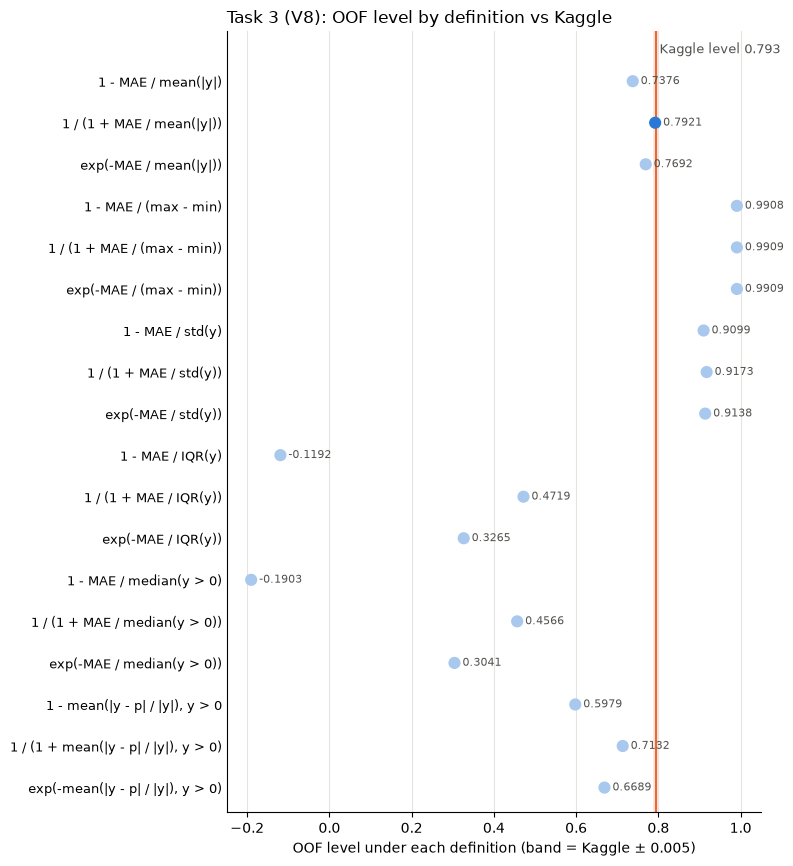

,OOF level,Kaggle,distance,consistent
1 / (1 + MAE / mean(|y|)),0.7921,0.793,-0.0009,yes
exp(-MAE / mean(|y|)),0.7692,0.793,-0.0238,
1 - MAE / mean(|y|),0.7376,0.793,-0.0554,
"1 / (1 + mean(|y - p| / |y|), y > 0)",0.7132,0.793,-0.0798,
1 - MAE / std(y),0.9099,0.793,+0.1169,
exp(-MAE / std(y)),0.9138,0.793,+0.1208,
"exp(-mean(|y - p| / |y|), y > 0)",0.6689,0.793,-0.1241,
1 / (1 + MAE / std(y)),0.9173,0.793,+0.1243,
"1 - mean(|y - p| / |y|), y > 0",0.5979,0.793,-0.1951,
1 - MAE / (max - min),0.9908,0.793,+0.1978,


In [6]:
def nmae_defs(y, p):
    mae = np.abs(y - p).mean()
    return {'MAE / mean(|y|)': mae / np.abs(y).mean(), 'MAE / (max - min)': mae / (y.max() - y.min()), 'MAE / std(y)': mae / y.std(),
            'MAE / IQR(y)': mae / np.subtract(*np.percentile(y, [75, 25])), 'MAE / median(y > 0)': mae / np.median(y[y > 0]),
            'mean(|y - p| / |y|), y > 0': np.mean(np.abs(y - p)[y > 0] / y[y > 0])}


t3_tables = {}
for name, path, champion, kaggle in (('V8', 'outputs/experiments/task3_v8/task3_oof.csv', 0.792138, KAGGLE['T3 (V8 refit)']),
                                     ('V9a', 'outputs/experiments/task3_v9a/task3_oof.csv', 0.794729, KAGGLE['T3 (V8 refit)'] + SWAPS.loc['T3', 'task delta (x5)'])):
    o = pd.read_csv(path)
    y3, p3 = o['target'].to_numpy(), o['prediction'].to_numpy()
    assert abs(_score(y3, p3) - champion) < 1e-5, f'{name} OOF does not reproduce champion.json'
    rows = {}
    for d, v in nmae_defs(y3, p3).items():
        rows[f'1 - {d}'] = 1 - v
        rows[f'1 / (1 + {d})'] = 1 / (1 + v)
        rows[f'exp(-{d})'] = np.exp(-v)
    t3_tables[name] = level_table(rows, kaggle)
    print(f"{name}: MAE {np.abs(y3 - p3).mean():,.0f} THB | mean(y) {y3.mean():,.0f} | consistent: {list(t3_tables[name].index[t3_tables[name]['consistent'] == 'yes'])}")
plot_levels(t3_tables['V8'], KAGGLE['T3 (V8 refit)'], 'Task 3 (V8): OOF level by definition vs Kaggle')
t3_tables['V8'].sort_values('distance', key=abs).style.format({'OOF level': '{:.4f}', 'Kaggle': '{:.3f}', 'distance': '{:+.4f}'}) \
    .set_caption('Task 3 (V8 OOF): score under each NMAE definition, closest first')

In [7]:
t3_tables['V9a'].sort_values('distance', key=abs).head(5).style.format({'OOF level': '{:.4f}', 'Kaggle': '{:.4f}', 'distance': '{:+.4f}'}) \
    .set_caption('Task 3 (V9a OOF): five closest definitions (Kaggle = V8 level + V9a swap)')

,OOF level,Kaggle,distance,consistent
1 / (1 + MAE / mean(|y|)),0.7947,0.7943,+0.0004,yes
exp(-MAE / mean(|y|)),0.7724,0.7943,-0.0219,
1 - MAE / mean(|y|),0.7417,0.7943,-0.0526,
"1 / (1 + mean(|y - p| / |y|), y > 0)",0.7155,0.7943,-0.0788,
1 - MAE / std(y),0.9113,0.7943,+0.1170,


**NOTE:**


**Only 1 / (1 + MAE / mean(y)) is consistent**, and it is exactly what the pipeline already uses (`pis.tabular._score`). For V8 it gives 0.7921 vs Kaggle 0.793 (−0.0009), and for V9a 0.7947 vs 0.7943 (+0.0004). Every other normalisation or transform is at least 0.02 away: exp(−NMAE) 0.769, 1 − NMAE 0.738, MAPE-style 0.713, and the range or std normalisations are above 0.9. The targets are non-negative, so mean(|y|) = mean(y).

## 4. Task 4 (Overview: F1 Macro)

OOF ของ ens18 (logits ของ 5 fold ต่อสูตร) อยู่ในเครื่อง GPU ของเพื่อนในทีม ไม่มีใน repo หรือในเครื่องนี้ และเทรนใหม่ไม่ได้ (เครื่องนี้ไม่มี CUDA และไม่มีภาพ train) จึงใช้ F1 รายคลาสของ fold 0 ที่บันทึกไว้ใน `Task4/README.md` (branch `task4-boost`) กับจำนวนภาพ train ต่อคลาส คำนวณ macro และ weighted F1 ส่วน micro F1 (= accuracy) ต้องใช้ confusion matrix จึงประมาณได้แค่ช่วง

ตามที่ตกลงไว้ ไม่ทดสอบระดับของงานนี้ เพราะภาพ test ต่างจาก train (CV 0.96 ถึง 0.99 เทียบกับ Kaggle 0.824)

In [8]:
t4 = pd.DataFrame({'train images': [12429, 4407, 5596, 5926, 3188], 'fold-0 F1': [0.996, 0.990, 0.992, 0.990, 0.980]},
                  index=['7-11k', 'fiveN', 'freefried', 'pube', 'roblock'])
t4['train share'] = t4['train images'] / t4['train images'].sum()
macro4 = t4['fold-0 F1'].mean()
weighted4 = (t4['train share'] * t4['fold-0 F1']).sum()
test_pred_share = pd.read_csv('outputs/kaggle/best_082343.csv')['task4'].value_counts(normalize=True).sort_index()
t4['test prediction share (ens18)'] = test_pred_share.to_numpy()
print(f"fold-0: macro F1 {macro4:.4f} | weighted F1 {weighted4:.4f} | micro F1 (accuracy) about {weighted4:.3f} "
      f"(recall-weighted; equals weighted F1 when precision = recall per class) | spread {weighted4 - macro4:+.4f}")
t4.style.format({'train images': '{:,}', 'fold-0 F1': '{:.3f}', 'train share': '{:.1%}', 'test prediction share (ens18)': '{:.1%}'}) \
    .set_caption('Task 4: fold-0 per-class F1 (Task4/README.md on task4-boost) and class shares')

fold-0: macro F1 0.9896 | weighted F1 0.9917 | micro F1 (accuracy) about 0.992 (recall-weighted; equals weighted F1 when precision = recall per class) | spread +0.0021


,train images,fold-0 F1,train share,test prediction share (ens18)
7-11k,"12,429",0.996,39.4%,17.5%
fiveN,"4,407",0.990,14.0%,22.1%
freefried,"5,596",0.992,17.7%,16.2%
pube,"5,926",0.990,18.8%,28.4%
roblock,"3,188",0.980,10.1%,15.8%


**NOTE:**


**Not testable here.** The ens18 OOF logits are not on this machine, and there is no GPU or train images to rebuild them. With the fold-0 per-class F1 from `Task4/README.md`, macro F1 is 0.9896 and weighted F1 0.9917. Micro F1 is about the same, so the definitions differ by about 0.002 on validation data, and the level test is skipped by agreement.

The definition also cannot change a decision now. The rule is argmax, and on OOF at about 0.99 there is nothing to tune. The one place it could matter is the test class mix: predictions there are 17.5% 7-11k against 39% in train. Re-weighting classes from test predictions is not allowed, though. If a teammate wants a check, scoring the ens18 OOF with macro, weighted and micro F1 takes one line.

## 5. Task 5 (Overview: F3 Macro)

**binary หรือไม่:** datacard บอก `is_anomaly` เป็น binary (0 = ปกติ, 1 = ผิดปกติ) คอลัมน์ task5 ที่ส่งเป็น 0/1

**ไม่มี label:** Task 5 มีแค่ `test.csv` จึงไม่มี OOF ใช้ pseudo-label แทน: flag ของ detector v2 (`origin/task5-boost`, PR #22) ซึ่ง EDA ใน README ของ branch นั้นพบ anomaly 8 กลุ่ม 2,049 แถว และ v2 จับได้ 2,046 แถว (+51 แถวนอกกลุ่ม) เหมือนกันทุก seed สร้างด้วย `eda/make_t5_pseudo_labels.py` (git archive, ไม่ merge) ข้อจำกัด: pseudo-label มาจากโมเดล คะแนนของคอลัมน์อื่นจึงเป็นการประมาณ

คอลัมน์ที่เคยส่ง:
- IsolationForest flag 20% (`baseline/submission.csv`, ไฟล์ 0.72635)
- EB v1 auto 2,008 flag (`outputs/kaggle/main_baseline.csv`, คอลัมน์เดียวกับที่ทำให้ได้ 0.80097)
- EB v1 strong 2,140 flag (`outputs/kaggle/best_082343.csv`, คอลัมน์ปัจจุบัน)

นิยาม: macro F3, F3 ของคลาส anomaly (binary, pos_label = 1), F3 ของคลาสปกติ, weighted F3, micro (= accuracy)

In [9]:
t5_test = pd.read_csv(DEFAULT_DATA / '05_anomaly_detection' / 'test.csv', usecols=['player_id'])
v2 = pd.read_csv('outputs/experiments/metric_recheck/task5_v2_scores.csv')
assert (v2['player_id'].to_numpy() == t5_test['player_id'].to_numpy()).all(), 'v2 scores are not in test.csv order'
y5 = v2['prediction'].to_numpy().astype(int)
q5 = v2['anomaly_probability'].clip(0, 1).to_numpy()
print(f"pseudo-labels: {y5.sum():,} anomalies ({y5.mean():.2%}) | expected prevalence from the posteriors {q5.mean():.2%}")

COLUMNS = {'IF 20% (0.72635 file)': pd.read_csv('baseline/submission.csv')['task5'].to_numpy(),
           'EB v1 auto (gave 0.80097)': pd.read_csv('outputs/kaggle/main_baseline.csv')['task5'].to_numpy(),
           'EB v1 strong (current)': pd.read_csv('outputs/kaggle/best_082343.csv')['task5'].to_numpy()}


def task5_defs(y, pred):
    return {'macro F3': fbeta_score(y, pred, beta=3, average='macro'), 'F3 anomaly (binary)': fbeta_score(y, pred, beta=3),
            'F3 normal': fbeta_score(1 - y, 1 - pred, beta=3), 'weighted F3': fbeta_score(y, pred, beta=3, average='weighted'),
            'micro F3 (= accuracy)': accuracy_score(y, pred)}


t5_cols = pd.DataFrame({k: task5_defs(y5, p) for k, p in COLUMNS.items()})
t5_cols.loc['flags'] = [p.sum() for p in COLUMNS.values()]
t5_cols.style.format('{:.4f}').format('{:,.0f}', subset=pd.IndexSlice[['flags'], :]) \
    .set_caption('Task 5: submitted columns scored against the v2 pseudo-labels')

pseudo-labels: 2,097 anomalies (8.10%) | expected prevalence from the posteriors 7.92%


,IF 20% (0.72635 file),EB v1 auto (gave 0.80097),EB v1 strong (current)
macro F3,0.7167,0.9731,0.9756
F3 anomaly (binary),0.5813,0.9478,0.9566
F3 normal,0.8522,0.9984,0.9947
weighted F3,0.8302,0.9943,0.9916
micro F3 (= accuracy),0.8270,0.9943,0.9916
flags,"5,178","2,008","2,140"


In [10]:
current = COLUMNS['EB v1 strong (current)']
lv = task5_defs(y5, current)
t5_levels = pd.concat({'Kaggle 0.99 (prompt)': level_table(lv, 0.99), 'Kaggle 0.965 (docs)': level_table(lv, 0.965)}, axis=1)
delta = pd.Series(task5_defs(y5, COLUMNS['EB v1 auto (gave 0.80097)'])) - pd.Series(task5_defs(y5, COLUMNS['IF 20% (0.72635 file)']))
t5_delta = pd.DataFrame({'pseudo-label delta (IF -> EB v1 auto)': delta, 'Kaggle delta': SWAPS.loc['T5', 'task delta (x5)']})
t5_delta['gap'] = t5_delta.iloc[:, 0] - t5_delta['Kaggle delta']
t5_delta['consistent'] = np.where(t5_delta['gap'].abs() <= 0.02, 'yes', '')
display(t5_levels.style.format('{:.4f}', subset=pd.IndexSlice[:, [c for c in t5_levels.columns if c[1] in ('OOF level', 'Kaggle', 'distance')]])
        .set_caption('Task 5 levels: current column on pseudo-labels vs the two Kaggle levels on record'))
t5_delta.style.format({'pseudo-label delta (IF -> EB v1 auto)': '{:+.4f}', 'Kaggle delta': '{:+.4f}', 'gap': '{:+.4f}'}) \
    .set_caption('Task 5 swap IF -> EB v1 auto (Tasks 1-4 unchanged, commit d873cb8): delta per definition')

,pseudo-label delta (IF -> EB v1 auto),Kaggle delta,gap,consistent
macro F3,+0.2564,+0.3731,-0.1167,
F3 anomaly (binary),+0.3665,+0.3731,-0.0066,yes
F3 normal,+0.1462,+0.3731,-0.2269,
weighted F3,+0.1641,+0.3731,-0.2090,
micro F3 (= accuracy),+0.1673,+0.3731,-0.2058,


**ขอบเขตที่ไม่ขึ้นกับ label:** IsolationForest flag 20% ของแถว ต่อให้ label จริงเป็นแบบไหน คะแนนของคอลัมน์นั้นภายใต้นิยามที่เน้นคลาสปกติก็ต่ำได้ไม่เกินขีดหนึ่ง (กรณีแย่สุด: ทุกแถวที่ flag เป็นคลาสปกติ) ส่วน EB v1 ได้มากสุด 1.0 ส่วนต่าง IF → EB จึงมีเพดาน ถ้าเพดานต่ำกว่า +0.373 ที่ Kaggle ให้ นิยามนั้นตัดทิ้งได้เลยโดยไม่ต้องพึ่ง pseudo-label ลองทุก prevalence 5% ถึง 12%

คะแนนที่คาดหวังจาก posterior ของ v2 (ไม่ใช้ flag ตัดที่ 0.5) ให้ระดับของคอลัมน์ปัจจุบันอีกแบบ

In [11]:
n5, k_if = len(y5), int(COLUMNS['IF 20% (0.72635 file)'].sum())
rows = []
for prev in (0.05, 0.08, 0.10, 0.12):
    a = round(prev * n5); normal = n5 - a
    # Worst case for IF: every flagged row is normal and every anomaly is missed.
    tn = normal - k_if
    prec_n = tn / (n5 - k_if); rec_n = tn / normal    # normal class as the positive class
    f3_normal = 10 * prec_n * rec_n / (9 * prec_n + rec_n)
    weighted = (normal / n5) * f3_normal              # anomaly F3 = 0 in the worst case
    acc = (n5 - k_if - a) / n5
    rows.append({'prevalence': prev, 'max delta F3 normal': 1 - f3_normal, 'max delta weighted F3': 1 - weighted,
                 'max delta micro (accuracy)': 1 - acc, 'max delta macro F3': 1 - f3_normal / 2, 'max delta F3 anomaly': 1.0})
bounds = pd.DataFrame(rows).set_index('prevalence')
print(f"Kaggle delta IF -> EB v1 auto: {SWAPS.loc['T5', 'task delta (x5)']:+.4f}; a definition whose max delta is below it is ruled out")
display(bounds.style.format('{:.3f}').format_index('{:.0%}').set_caption('Largest possible IF -> EB gain under each definition (any labels)'))

# Expected level of the current column from the v2 posteriors (soft labels instead of flags).
cur = current.astype(bool)
tp = q5[cur].sum(); fp = cur.sum() - tp; fn = q5.sum() - tp; tn = (n5 - q5.sum()) - fp
ea = 10 * tp / (10 * tp + 9 * fn + fp); en = 10 * tn / (10 * tn + 9 * fp + fn)
soft = pd.Series({'macro F3': (ea + en) / 2, 'F3 anomaly (binary)': ea, 'F3 normal': en,
                  'weighted F3': (q5.sum() * ea + (n5 - q5.sum()) * en) / n5}, name='expected level (v2 posteriors)')
soft.to_frame().style.format('{:.4f}').set_caption('Task 5: current column, expected level from the v2 posteriors')

Kaggle delta IF -> EB v1 auto: +0.3731; a definition whose max delta is below it is ruled out


,max delta F3 normal,max delta weighted F3,max delta micro (accuracy),max delta macro F3,max delta F3 anomaly
prevalence,,,,,
5%,0.198,0.238,0.250,0.599,1.000
8%,0.207,0.270,0.280,0.604,1.000
10%,0.213,0.292,0.300,0.607,1.000
12%,0.220,0.314,0.320,0.610,1.000


,expected level (v2 posteriors)
macro F3,0.9792
F3 anomaly (binary),0.9644
F3 normal,0.9939
weighted F3,0.9916


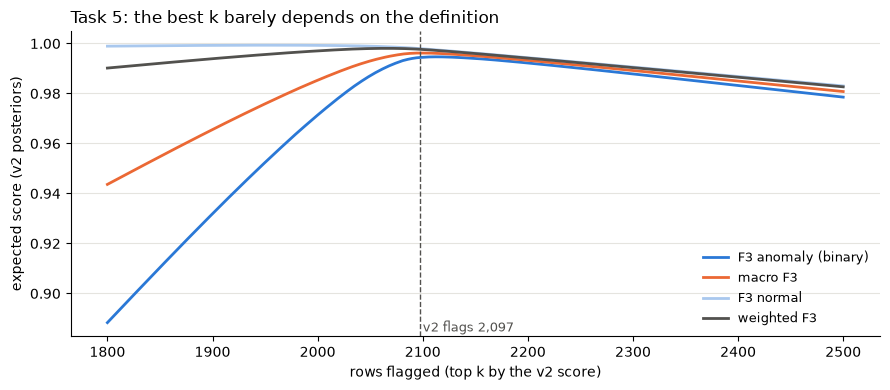

,best k,best share,E[score] at best k,"E[score] at k = 2,097 (v2)","E[score] at k = 2,140"
F3 anomaly (binary),"2,114",8.17%,0.9947,0.9944,0.9943
macro F3,"2,097",8.10%,0.9962,0.9962,0.9954
F3 normal,"1,956",7.56%,0.9993,0.9980,0.9965
weighted F3,"2,066",7.98%,0.9981,0.9977,0.9963


In [12]:
# Label-free check: expected score of flagging the top k rows under each definition, from the v2 posteriors.
order = np.argsort(-v2['anomaly_score'].to_numpy(), kind='stable')
cq = np.r_[0, np.cumsum(q5[order])]
P, n = q5.sum(), len(q5)
ks = np.arange(1, n)
tp = cq[ks]; fp = ks - tp; fn = P - tp; tn = (n - P) - fp
fa = 10 * tp / (10 * tp + 9 * fn + fp)
fnorm = 10 * tn / (10 * tn + 9 * fp + fn)
expected = {'F3 anomaly (binary)': fa, 'macro F3': (fa + fnorm) / 2, 'F3 normal': fnorm, 'weighted F3': (P * fa + (n - P) * fnorm) / n}
best = pd.DataFrame({d: {'best k': int(ks[s.argmax()]), 'best share': ks[s.argmax()] / n, 'E[score] at best k': s.max(),
                         'E[score] at k = 2,097 (v2)': s[2096], 'E[score] at k = 2,140': s[2139]} for d, s in expected.items()}).T

fig, ax = plt.subplots(figsize=(9, 4))
window = (ks >= 1800) & (ks <= 2500)
for (d, s), c in zip(expected.items(), [BLUE, ORANGE, '#a9c8ee', INK]):
    ax.plot(ks[window], s[window], color=c, linewidth=2, label=d)
ax.axvline(2097, color=INK, linestyle='--', linewidth=1)
ax.text(2100, ax.get_ylim()[0] + 0.002, 'v2 flags 2,097', fontsize=9, color=INK)
ax.set_xlabel('rows flagged (top k by the v2 score)')
ax.set_ylabel('expected score (v2 posteriors)')
ax.set_title('Task 5: the best k barely depends on the definition', loc='left')
ax.legend(frameon=False, fontsize=9)
tidy(ax, 'y')
plt.tight_layout()
plt.show()
best.style.format({'best k': '{:,.0f}','best share': '{:.2%}', 'E[score] at best k': '{:.4f}', 'E[score] at k = 2,097 (v2)': '{:.4f}',
                   'E[score] at k = 2,140': '{:.4f}'}).set_caption('Task 5: label-free expected score by flag count')

**NOTE:**


**Task 5 is binary.** `is_anomaly` is 0/1 and the submission column is 0/1.

**Levels are inconclusive.** Task 5 has no labels, and the two Kaggle levels on record disagree: 0.965 (docs) and ~0.99 (prompt). Both look like residuals (5 × total minus the other four tasks), so they inherit the Task 1 assumption: T1 at macro ~0.78 gives T5 ≈ 0.965, T1 at binary ~0.76 gives T5 ≈ 0.99. Against the v2 pseudo-labels, the current column scores anomaly F3 0.957, macro 0.976, weighted 0.992 and normal 0.995; the expected scores from the soft posteriors are similar (anomaly 0.964, macro 0.979). The verdict flips with whichever Kaggle level is used.

**The clean swap decides it.** IsolationForest → EB v1 changed only Task 5 (commit d873cb8) and moved it by +0.373 on Kaggle.
- On pseudo-labels, anomaly-class F3 moves +0.367 (gap 0.007); macro F3 moves +0.256 (gap 0.117).
- Normal-class, weighted and micro F3 are ruled out with no labels at all: IsolationForest flags 20% of rows, so even in the worst case those scores stay high, and the largest possible gain is 0.20 to 0.32 for any prevalence from 5% to 12%. That is below +0.373.
- Macro F3 could only reach +0.373 if the pseudo-labels were badly wrong for the IsolationForest column (its anomaly F3 would need to be about 0.35 instead of 0.58).

So Task 5 is most likely **F3 of the anomaly class**: the same "Macro on the Overview, binary in the scorer" pattern as Task 1.

**It does not change the decision rule.** The v2 posteriors are nearly 0/1, so the best number of flags is 2,114 under anomaly F3 and 2,097 under macro F3. The expected score at 2,097 is lower by only 0.0003. That is unlike Task 1, where the metric moved the threshold from 0.38 to 0.18.

## 6. Probes (step 2)

กฎ: ทำ probe เฉพาะงานที่มีนิยาม consistent มากกว่าหนึ่งแบบหรือไม่มีเลย และต้องหา submission ที่แยกสมมติฐานได้ > 0.003 บนงานนั้น โดยปรับกฎตัดสินบน OOF ตามแต่ละนิยามแล้วทำนายคะแนน

ตารางด้านล่างคือคะแนนของ probe วินิจฉัยหนึ่งแบบสำหรับงาน 5 (flag ทุกแถว) ภายใต้แต่ละนิยาม คิดจาก prevalence ของ pseudo-label เก็บไว้เผื่อใช้ ไม่ได้สร้างไฟล์ ดูเหตุผลใน NOTE

In [13]:
pi = y5.mean()
fa_all = 10 * pi / (9 * pi + 1)  # F3 of the anomaly class when every row is flagged
flag_all = pd.Series({'F3 anomaly (binary)': fa_all, 'macro F3': fa_all / 2, 'F3 normal': 0.0, 'weighted F3': pi * fa_all})
probe = pd.DataFrame({'task score if all rows flagged': flag_all,
                      'current level (pseudo-labels)': pd.Series(task5_defs(y5, current))[flag_all.index]})
probe['total change (task delta / 5)'] = (probe.iloc[:, 0] - probe.iloc[:, 1]) / 5
probe.style.format('{:.4f}').format('{:+.4f}', subset=['total change (task delta / 5)']) \
    .set_caption(f'Optional Task 5 diagnostic probe: flag every row (prevalence {pi:.2%})')

,task score if all rows flagged,current level (pseudo-labels),total change (task delta / 5)
F3 anomaly (binary),0.4685,0.9566,-0.0976
macro F3,0.2342,0.9756,-0.1483
F3 normal,0.0000,0.9947,-0.1989
weighted F3,0.0379,0.9916,-0.1907


**NOTE:**


**No probe is needed, so none is built.**
- Task 2 and Task 3 have exactly one consistent definition each.
- Task 4 cannot be tested here, and no rule tuned on OOF depends on its definition.
- Task 5 is settled by the clean swap plus the label-free bounds. More importantly, a rule tuned for anomaly F3 or for macro F3 gives the same submission within 17 rows (expected difference 0.0003 < 0.003). So no tuned submission can separate the two hypotheses by more than 0.003, and none is worth a probe.

The table above is kept as an optional diagnostic only: flagging every row scores about 0.47 under anomaly F3 and 0.23 under macro F3 (total change −0.098 vs −0.148). It would confirm the metric but change nothing we would submit, so it is not built. Building it would also need the 0.83699 file, which is not in the repo or `outputs/kaggle/`.

## Summary

| งาน | Overview | consistent (ระดับคะแนน) | หลักฐานเพิ่ม | metric ที่น่าจะใช้จริง | ต้องเปลี่ยนอะไรไหม |
|---|---|---|---|---|---|
| 1 | F2 (Macro) | F2 ของคลาสคนโกง (OOF 0.763 กับ ~0.76) | ส่วนต่างตอนลด threshold: คนโกง +0.075 กับ Kaggle +0.068, macro −0.064 | **F2 ของคลาสคนโกง** (ยืนยันแล้ว) | เปลี่ยนแล้ว (080d9a0) |
| 2 | F1 (Macro) | **macro F1 เท่านั้น** (0.7567 กับ 0.753) | ส่วนต่างแยกไม่ได้ (ทุกนิยาม +0.004 ถึง +0.005) | **macro F1** | ไม่ต้อง |
| 3 | NMAE | **1 / (1 + MAE / mean(y)) เท่านั้น** (V8 0.7921 กับ 0.793, V9a 0.7947 กับ 0.7943) | แบบอื่นห่างเกิน 0.02 | **1 / (1 + MAE / mean(y))** ตรงกับ `pis.tabular._score` | ไม่ต้อง |
| 4 | F1 (Macro) | ไม่ได้ทดสอบ (ภาพ test ต่างจาก train, ไม่มี OOF ของ ens18 ในเครื่องนี้) | fold 0: macro 0.990, weighted 0.992 | macro F1 (ยืนยันไม่ได้) | ไม่ต้อง: กฎ argmax ไม่มีอะไรให้ปรับบน OOF |
| 5 | F3 (Macro) | ตัดสินไม่ได้: ระดับบน Kaggle ไม่แน่นอน (0.965 กับ 0.99) | สลับ IF → EB +0.373: F3 anomaly +0.367 ตรง, macro +0.256 ไม่ตรง, normal/weighted/micro เป็นไปไม่ได้ (เพดาน ≤ 0.32 ไม่ว่า label เป็นแบบไหน) | **F3 ของคลาส anomaly** (น่าจะ เหมือนงาน 1) | ไม่ต้อง: จำนวน flag ที่ดีที่สุด 2,097 ถึง 2,114 ทั้งสองนิยาม ต่างกัน 0.0003 |

**Decision**
- งาน 2 และ 3: metric ที่ทีมใช้อยู่ถูกแล้ว ไม่ต้องทำอะไร
- งาน 4: ทดสอบไม่ได้และไม่มีผลกับการตัดสินใจ ไม่ใช้โควตา
- งาน 5: น่าจะเป็น F3 แบบ binary ของคลาส anomaly แต่กฎเลือกจำนวน flag ให้ผลเกือบเท่ากันทั้งสองนิยาม จึงไม่มีอะไรให้ปรับ ไม่ทำ probe ข้อนี้ควรเขียนไว้ในรายงานคู่กับงาน 1
- **ไม่มี probe** (ใช้ 0 จาก 2 ครั้ง) และไม่มีขั้นที่ 3 เพราะไม่มีงานไหนที่ต้องปรับกฎตาม metric ใหม่
- ถ้าอยากยืนยันงาน 5 จริงๆ ก็มี probe วินิจฉัย (flag ทุกแถว, ส่วน 6) แต่ไม่เปลี่ยนสิ่งที่จะส่ง จึงไม่แนะนำ